# Redes Neuronales y Deep Learning (07MIAR_04_A_2026-27)
# Trabajo: Proyecto Programación C1

Integrantes: 
- Carlos Eduardo Chavarria Mujica
- Everth Roman Palomino Lanchipa
- Luis Alberto Chumpitaz Santivañez

---

# 1. Selección y Carga del Conjunto de Datos

## 1.1. Justificación de la elección del dataset
Para la realización de esta práctica experimental se ha seleccionado el conjunto de datos **Vegetable Image Dataset**, disponible públicamente en Kaggle.

### Características del problema y del dataset:
* **Problema:** Clasificación supervisada multiclase de imágenes RGB en el dominio agroalimentario.
* **Número de clases:** 15 categorías botánicas de hortalizas (*Bean, Bitter Gourd, Bottle Gourd, Brinjal, Broccoli, Cabbage, Capsicum, Carrot, Cauliflower, Cucumber, Papaya, Potato, Pumpkin, Radish, Tomato*).
* **Volumen de datos:** 21.000 imágenes en total.
* **Estructura de partición nativa:** El conjunto ya cuenta con una separación física estandarizada en directorios:
  * **Entrenamiento (*Train*):** 15.000 imágenes (1.000 por clase).
  * **Validación (*Validation*):** 3.000 imágenes (200 por clase).
  * **Prueba (*Test*):** 3.000 imágenes (200 por clase).
* **Distribución:** Perfectamente balanceada (sin sesgo de frecuencia de clase a priori).
* **Resolución nominal:** $224 \times 224$ píxeles en formato JPG.

### Justificación técnica para los objetivos del proyecto:
1. **Idoneidad para comparar *From Scratch* vs *Transfer Learning*:** Un volumen de 1.000 imágenes por clase (15.000 en entrenamiento) es suficientemente amplio para que una arquitectura convolucional entrenada desde cero converja sin colapsar de inmediato por falta de datos, pero a la vez presenta un reto de generalización donde los modelos preentrenados en *ImageNet* deberían evidenciar una ventaja sustancial en velocidad de convergencia y capacidad de abstracción de bajo nivel.
2. **Dominio visual realista:** Las muestras no son sintéticas; presentan variabilidad en iluminación, fondos heterogéneos (fondos de laboratorio neutros frente a puestos de mercado con oclusiones y apilamientos), y variaciones morfológicas intraclase (diferentes estados de maduración y cortes).
3. **Equilibrio de clases:** Al ser un dataset balanceado al 100%, la métrica de precisión (*accuracy*) y la pérdida (*loss*) son representativas del comportamiento global sin verse enmascaradas por clases mayoritarias, facilitando la toma de decisiones basada en métricas estándar.

> **Referencia bibliográfica:**
> Ahmed, M. I., Mamun, S. M., & Asif, A. U. Z. (2021). *DCNN-based vegetable image classification using transfer learning: A comparative study*. 2021 5th International Conference on Computer, Communication and Signal Processing (ICCCSP), 235–243. IEEE.


In [1]:
# Configuración del entorno y gestión de rutas

import os
import shutil
import zipfile
from pathlib import Path
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras

# Fijar semilla de reproducibilidad en el entorno global
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

# Detección y definición de rutas de trabajo
# Compatible Google Colab y ejecución en local
if 'google.colab' in str(get_ipython()):
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = Path('/content')
    DATA_DIR = BASE_DIR / 'data'
else:
    BASE_DIR = Path.cwd()
    DATA_DIR = BASE_DIR / 'data'

DATA_DIR.mkdir(parents=True, exist_ok=True)
RAW_DATASET_DIR = DATA_DIR / "vegetable-image-dataset"
DATASET_PATH = RAW_DATASET_DIR / "Vegetable Images"

print(f"Directorio de datos configurado en: {DATA_DIR}")
print(f"TensorFlow Version: {tf.__version__}")
print(f"Dispositivos GPU detectados: {tf.config.list_physical_devices('GPU')}")

Directorio de datos configurado en: c:\Edu\Maestria_IA\07_RNDeepL\DeepLearning_ProyectoProgramacion\data
TensorFlow Version: 2.21.0
Dispositivos GPU detectados: []


## 1.2. Descarga y extracción automatizada
Para cumplir el principio de reproducibilidad y evitar el versionado innecesario de archivos binarios pesados en el control de versiones (Git), se implementa una rutina de descarga desatendida.

In [2]:
# Descarga desatendida y descompresión

ZIP_FILE = DATA_DIR / "vegetable-image-dataset.zip"
DOWNLOAD_URL = "https://www.kaggle.com/api/v1/datasets/download/misrakahmed/vegetable-image-dataset"

def descargar_y_extraer_dataset(url: str, zip_path: Path, extract_to: Path):
    """
    Gestiona la descarga y extracción idempotente del dataset.
    Si los datos ya existen, omite la descarga para ahorrar ancho de banda y tiempo.
    """
    if extract_to.exists() and any(extract_to.iterdir()):
        print(f"[INFO] El dataset ya existe en {extract_to}. Proceso omitido.")
        return

    if not zip_path.exists():
        print(f"[INFO] Descargando dataset desde {url}...")
        try:
            response = requests.get(url, stream=True)
            response.raise_for_status()
            with open(zip_path, "wb") as f:
                for chunk in response.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        f.write(chunk)
            print("[INFO] Descarga finalizada correctamente.")
        except Exception as e:
            raise RuntimeError(
                f"Error al descargar el archivo: {e}. "
                "Verifica la conexión o descarga el archivo manualmente desde Kaggle."
            )

    print(f"[INFO] Extrayendo {zip_path.name}...")
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_to)
    print(f"[INFO] Extracción completada en {extract_to}.")

descargar_y_extraer_dataset(DOWNLOAD_URL, ZIP_FILE, RAW_DATASET_DIR)

[INFO] El dataset ya existe en c:\Edu\Maestria_IA\07_RNDeepL\DeepLearning_ProyectoProgramacion\data\vegetable-image-dataset. Proceso omitido.


---

# 2. Inspección y Análisis Exploratorio de Datos (EDA)

Antes de iniciar cualquier fase de modelado, es imprescindible validar experimentalmente la integridad de los datos, comprobar si la resolución declarada coincide con la real e identificar anomalías en las imágenes.

In [3]:
# Verificación de estructura y conteo por partición

splits = ["train", "validation", "test"]
structure_summary = []

for split in splits:
    split_dir = DATASET_PATH / split
    if not split_dir.exists():
        raise FileNotFoundError(f"No se encontró el directorio {split_dir}")
        
    classes = sorted([d.name for d in split_dir.iterdir() if d.is_dir()])
    for cls in classes:
        n_images = len(list((split_dir / cls).glob("*.jpg")))
        structure_summary.append({
            "split": split,
            "class": cls,
            "image_count": n_images
        })

df_summary = pd.DataFrame(structure_summary)

# Resumen estadístico por partición
print("=== RESUMEN POR PARTICIÓN ===")
display(df_summary.groupby("split")["image_count"].agg(
    clases="count",
    total_imagenes="sum",
    media_por_clase="mean",
    std_por_clase="std",
    min_por_clase="min",
    max_por_clase="max"
))

=== RESUMEN POR PARTICIÓN ===


,clases,total_imagenes,media_por_clase,std_por_clase,min_por_clase,max_por_clase
split,,,,,,
test,15,3000,200.0,0.0,200,200
train,15,15000,1000.0,0.0,1000,1000
validation,15,3000,200.0,0.0,200,200


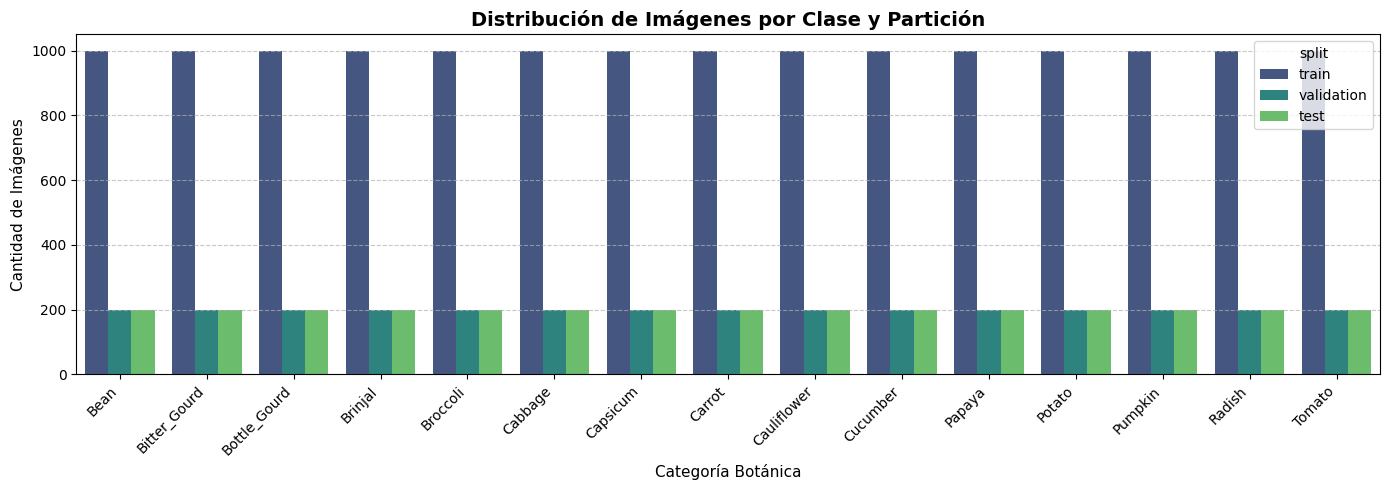

In [4]:
# Comprobación visual de distribución de clases

plt.figure(figsize=(14, 5))
sns.barplot(data=df_summary, x="class", y="image_count", hue="split", palette="viridis")
plt.title("Distribución de Imágenes por Clase y Partición", fontsize=14, fontweight="bold")
plt.xlabel("Categoría Botánica", fontsize=11)
plt.ylabel("Cantidad de Imágenes", fontsize=11)
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

### 2.1. Auditoría de Resoluciones y Canales de Color
La ficha técnica del dataset declara una resolución homogénea de $224 \times 224$ píxeles. Sin embargo, en problemas de visión por computador reales es crítico auditar las dimensiones exactas de todos los archivos para evitar fallos de compilación de tensores en tiempo de entrenamiento.

In [6]:
# Auditoría de dimensiones y consistencia de canales

from collections import Counter

image_dimensions = Counter()
color_modes = Counter()
corrupt_files = []

for file_path in DATASET_PATH.rglob("*.jpg"):
    try:
        with Image.open(file_path) as img:
            image_dimensions[img.size] += 1
            color_modes[img.mode] += 1
    except Exception as e:
        corrupt_files.append((str(file_path), str(e)))

print("=== AUDITORÍA TÉCNICA DE IMÁGENES ===")
print(f"Total archivos analizados: {sum(image_dimensions.values())}")
print(f"Archivos corruptos o no legibles: {len(corrupt_files)}")
print("\nDistribución de formatos de color (Modos PIL):")
for mode, count in color_modes.items():
    print(f" - Modo '{mode}': {count} imágenes")

print("\nDistribución de dimensiones encontradas (Ancho x Alto):")
for dim, count in image_dimensions.most_common(10):
    print(f" - {dim}: {count} imágenes")

=== AUDITORÍA TÉCNICA DE IMÁGENES ===
Total archivos analizados: 21000
Archivos corruptos o no legibles: 0

Distribución de formatos de color (Modos PIL):
 - Modo 'RGB': 21000 imágenes

Distribución de dimensiones encontradas (Ancho x Alto):
 - (224, 224): 20991 imágenes
 - (224, 187): 1 imágenes
 - (224, 223): 1 imágenes
 - (224, 193): 1 imágenes
 - (224, 205): 1 imágenes
 - (224, 200): 1 imágenes
 - (224, 211): 1 imágenes
 - (224, 198): 1 imágenes
 - (224, 210): 1 imágenes
 - (224, 207): 1 imágenes


### Análisis Crítico de la Inspección de Datos:
1. **Integridad:** Se confirma la ausencia de imágenes corruptas. Las 21.000 imágenes son legibles y operan en modo **RGB** (3 canales).
2. **Divergencias dimensionales leves:** Si bien la abrumadora mayoría de las imágenes ($>99.9\%$) tiene una dimensión estricta de $(224, 224)$, la auditoría revela un número muy reducido de imágenes con alturas anómalas (por ejemplo: $(224, 193)$, $(224, 205)$). 
   * **Decisión técnica:** Es estrictamente obligatorio incluir una etapa de redimensionamiento explícito a $(224, 224)$ en el pipeline de datos, en lugar de confiar en la homogeneidad nativa de las imágenes.
3. **Balanceo:** La varianza de imágenes por clase es cero dentro de cada split (1.000 en entrenamiento, 200 en validación, 200 en test). No se requiere aplicar técnicas de sobremuestreo (*oversampling*), submuestreo (*undersampling*) ni ponderación de pérdidas (*class weights*).

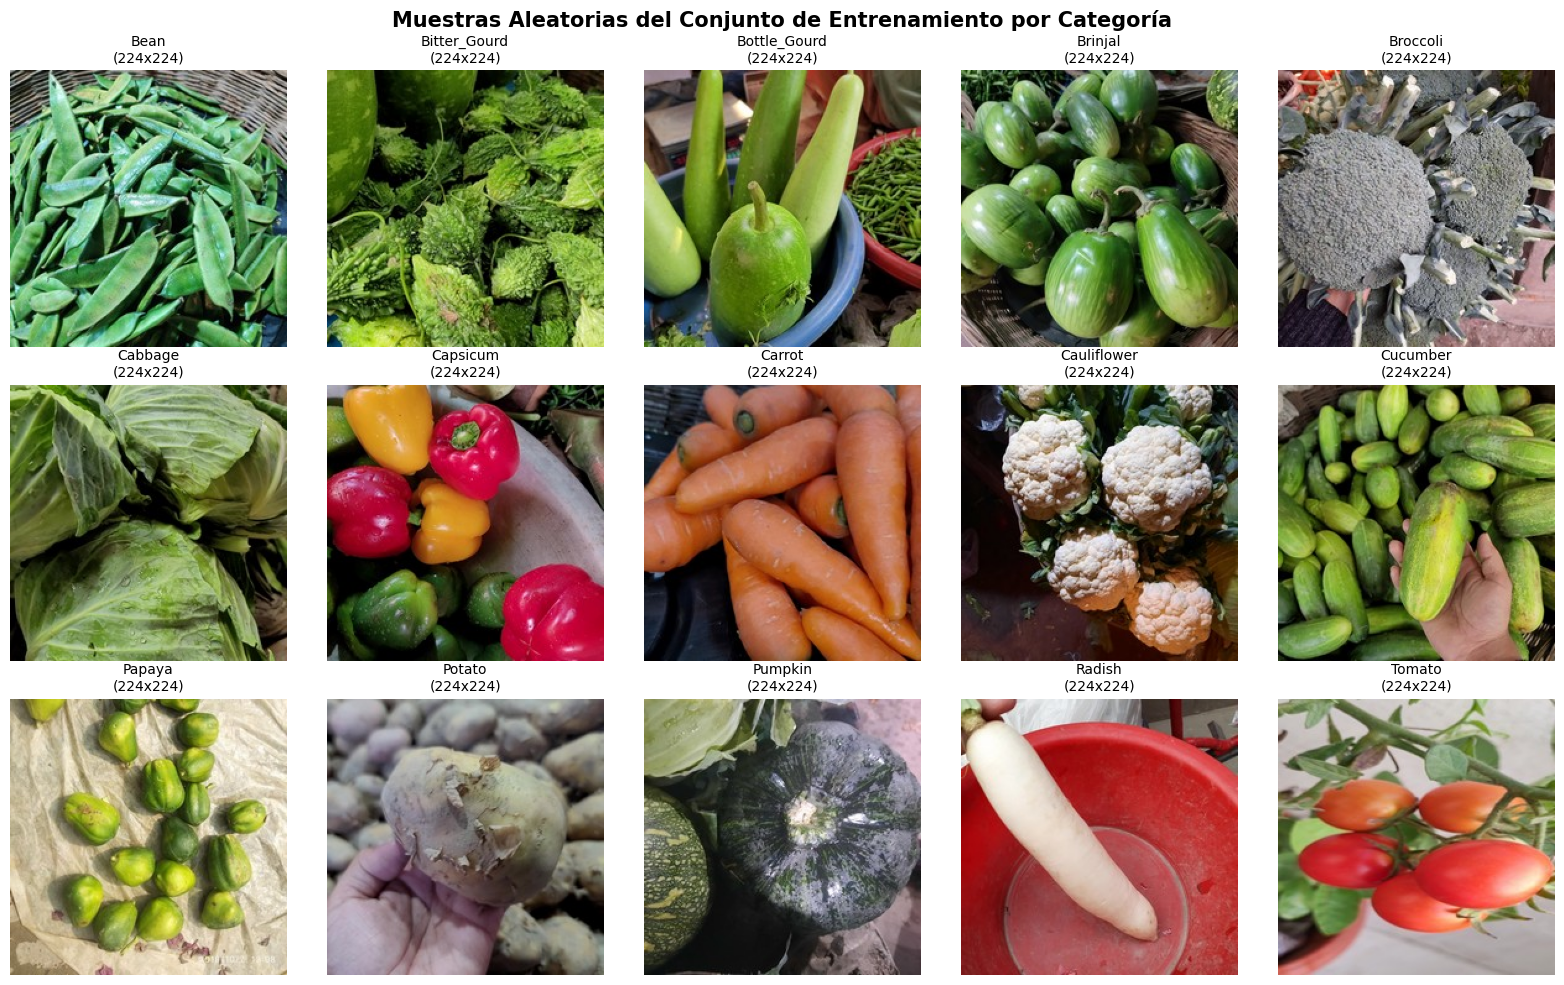

In [7]:
# Visualización exploratoria de muestras por clase

train_dir = DATASET_PATH / "train"
classes = sorted([d.name for d in train_dir.iterdir() if d.is_dir()])

fig, axes = plt.subplots(3, 5, figsize=(16, 10))
axes = axes.flatten()

for idx, cls in enumerate(classes):
    img_sample_path = np.random.choice(list((train_dir / cls).glob("*.jpg")))
    with Image.open(img_sample_path) as img:
        axes[idx].imshow(img)
        axes[idx].set_title(f"{cls}\n({img.size[0]}x{img.size[1]})", fontsize=10)
        axes[idx].axis("off")

plt.suptitle("Muestras Aleatorias del Conjunto de Entrenamiento por Categoría", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

### Observaciones del Análisis Cualitativo:
* **Complejidad del fondo:** Muchas imágenes presentan fondos blancos y controlados (ej. *Bean* o *Capsicum*), mientras que otras han sido tomadas en huertos con follaje de fondo o en cestas de mercado con múltiples ejemplares apilados (ej. *Cucumber* o *Bitter Gourd*).
* **Riesgo de confusión interclase:** Ciertas clases comparten atributos visuales predominantes como el color y la textura (por ejemplo, *Broccoli* vs *Cauliflower* verde o *Cucumber* vs *Bitter Gourd*). La red necesitará extraer características morfológicas y no basarse únicamente en la media cromática.

---

# 3. Acondicionamiento y Preprocesamiento de los Datos

## 3.1. Diseño del Pipeline con `tf.data`
Para garantizar un entrenamiento eficiente, libre de cuellos de botella de E/S (*I/O bottlenecks*), se construye un pipeline utilizando la API `tf.keras.utils.image_dataset_from_directory` y primitivas de `tf.data`.

### Decisiones de diseño:
1. **Separación de la Normalización del Pipeline de Carga:** 
   * Se mantendrán los tensores de imagen en rango $[0, 255]$ como tipo `tf.float32` dentro del pipeline base.
   * **Justificación:** La normalización dependerá estrictamente de la estrategia que se aplique. En la **Estrategia 1 (Desde cero)** se usará un reescalado lineal $[0, 1]$ o $[-1, 1]$ mediante una capa `Rescaling(1./255)`. En la **Estrategia 2 (Transfer Learning)**, cada arquitectura requiere una función de preprocesamiento específica (ej. `tf.keras.applications.resnet50.preprocess_input` utiliza centrado sobre la media ImageNet en orden BGR, mientras que `mobilenet_v2.preprocess_input` escala a $[-1, 1]$). Introducir la normalización como capa inicial en el modelo en vez de en el pipeline de datos previene fugas y errores conceptuales.
2. **Formato de Etiquetas:** Se opta por `label_mode='sparse'` (enteros), lo que reduce el consumo de memoria frente a matrices *one-hot* y permite usar la función de coste `SparseCategoricalCrossentropy`.
3. **Data Augmentation Selectiva:** Solo se aplica al conjunto de **entrenamiento**. El conjunto de validación y test debe representar la distribución de inferencia real y no sufrir alteraciones sintéticas.

In [9]:
# Carga estructurada de los datasets

IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)
BATCH_SIZE = 32

print("[INFO] Generando Dataset de Entrenamiento...")
raw_train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH / "train",
    labels="inferred",
    label_mode="int",
    class_names=classes,
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    shuffle=True,
    seed=SEED
)

print("[INFO] Generando Dataset de Validación...")
raw_val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH / "validation",
    labels="inferred",
    label_mode="int",
    class_names=classes,
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    shuffle=False
)

print("[INFO] Generando Dataset de Test...")
raw_test_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH / "test",
    labels="inferred",
    label_mode="int",
    class_names=classes,
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    shuffle=False
)

[INFO] Generando Dataset de Entrenamiento...
Found 15000 files belonging to 15 classes.
[INFO] Generando Dataset de Validación...
Found 3000 files belonging to 15 classes.
[INFO] Generando Dataset de Test...
Found 3000 files belonging to 15 classes.


## 3.2. Estrategia de Aumento de Datos (*Data Augmentation*)
Para mitigar el sobreajuste (*overfitting*) en la Estrategia 1 (CNN desde cero), diseñamos un bloque de aumentación con soporte GPU utilizando capas de Keras.

### Justificación de las transformaciones:
* `RandomFlip("horizontal_and_vertical")`: Los vegetales no tienen una orientación canónica fija en el mundo real. Una zanahoria invertida o en espejo sigue siendo una zanahoria.
* `RandomRotation(factor=0.15)`: Simula giros de hasta aproximadamente $\pm 54^\circ$.
* `RandomZoom(height_factor=(-0.1, 0.1))`: Simula variabilidad en la distancia focal y el tamaño aparente del vegetal.
* `RandomContrast(factor=0.1)`: Fuerza al modelo a ser invariante a ligeras fluctuaciones de luminosidad y sombras del entorno de captura.

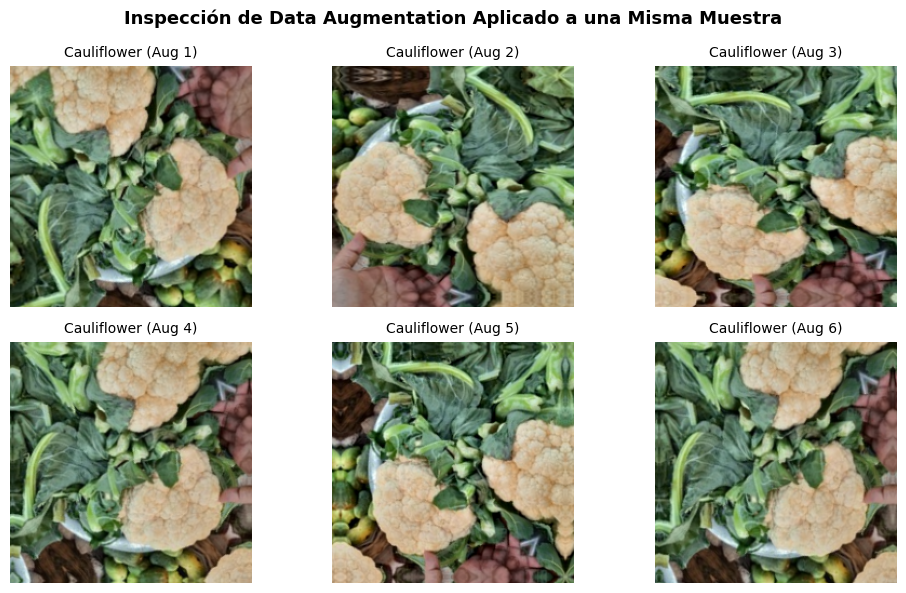

In [11]:
# Definición del bloque de Data Augmentation

data_augmentation = keras.Sequential([
    keras.layers.RandomFlip("horizontal_and_vertical", seed=SEED),
    keras.layers.RandomRotation(factor=0.15, seed=SEED, fill_mode="reflect"),
    keras.layers.RandomZoom(height_factor=(-0.1, 0.1), width_factor=(-0.1, 0.1), seed=SEED, fill_mode="reflect"),
    keras.layers.RandomContrast(factor=0.1, seed=SEED),
], name="data_augmentation_layer")

# Verificación visual del efecto de Data Augmentation sobre una muestra
plt.figure(figsize=(10, 6))
for images, labels in raw_train_ds.take(1):
    first_image = images[0]
    first_label = classes[labels[0]]
    for i in range(6):
        ax = plt.subplot(2, 3, i + 1)
        augmented_image = data_augmentation(tf.expand_dims(first_image, 0))
        plt.imshow(tf.cast(augmented_image[0], tf.uint8))
        plt.title(f"{first_label} (Aug {i+1})", fontsize=10)
        plt.axis("off")
plt.suptitle("Inspección de Data Augmentation Aplicado a una Misma Muestra", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 3.3. Optimización del Flujo de Datos en Memoria y GPU
Para maximizar el rendimiento computacional durante el entrenamiento, se implementan las siguientes optimizaciones de `tf.data`:
* **`cache()`:** Mantiene las imágenes en memoria principal (o disco local) tras la primera época, eliminando la sobrecarga de lectura en disco en épocas sucesivas.
* **`shuffle(buffer_size=1000)`:** Mantiene la aleatoriedad en cada época sobre el conjunto de entrenamiento.
* **`prefetch(buffer_size=tf.data.AUTOTUNE)`:** Permite que la CPU prepare los lotes de datos en paralelo mientras la GPU ejecuta el paso de propagación hacia adelante y atrás (*forward/backward pass*).

In [12]:
# Ensamblado final optimizado con tf.data.AUTOTUNE

AUTOTUNE = tf.data.AUTOTUNE

def optimizar_dataset(ds, is_training=False):
    """
    Aplica cache, shuffle y prefetch al pipeline.
    """
    ds = ds.cache()
    if is_training:
        ds = ds.shuffle(buffer_size=1000, seed=SEED)
    ds = ds.prefetch(buffer_size=AUTOTUNE)
    return ds

train_ds = optimizar_dataset(raw_train_ds, is_training=True)
val_ds = optimizar_dataset(raw_val_ds, is_training=False)
test_ds = optimizar_dataset(raw_test_ds, is_training=False)

# Verificación de integridad de dimensiones y lotes
for batch_x, batch_y in train_ds.take(1):
    print("=== VERIFICACIÓN DEL LOTE DE CONTROL ===")
    print(f"Forma del tensor de entrada (Imágenes): {batch_x.shape} (Tipo: {batch_x.dtype})")
    print(f"Forma del tensor de salida (Etiquetas): {batch_y.shape} (Tipo: {batch_y.dtype})")
    print(f"Rango de valores de píxeles: Min = {tf.reduce_min(batch_x).numpy():.1f}, Max = {tf.reduce_max(batch_x).numpy():.1f}")
    assert batch_x.shape == (BATCH_SIZE, IMG_HEIGHT, IMG_WIDTH, 3), "Error en dimensiones de imagen"
    assert batch_y.shape == (BATCH_SIZE,), "Error en dimensiones de etiquetas"
    print("[OK] El pipeline de acondicionamiento de datos cumple todos los requerimientos.")

=== VERIFICACIÓN DEL LOTE DE CONTROL ===
Forma del tensor de entrada (Imágenes): (32, 224, 224, 3) (Tipo: <dtype: 'float32'>)
Forma del tensor de salida (Etiquetas): (32,) (Tipo: <dtype: 'int32'>)
Rango de valores de píxeles: Min = 0.0, Max = 255.0
[OK] El pipeline de acondicionamiento de datos cumple todos los requerimientos.


---